The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


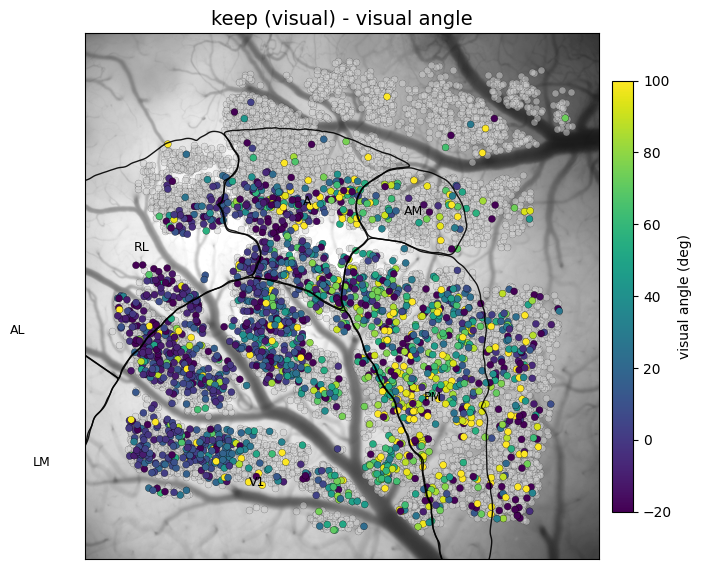

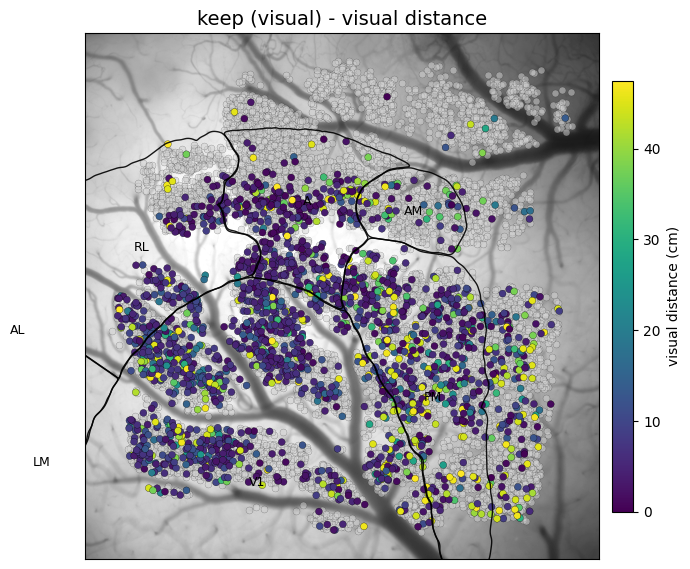

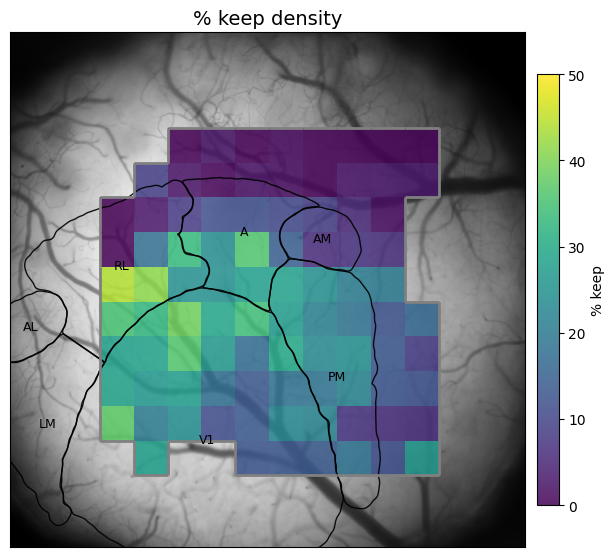

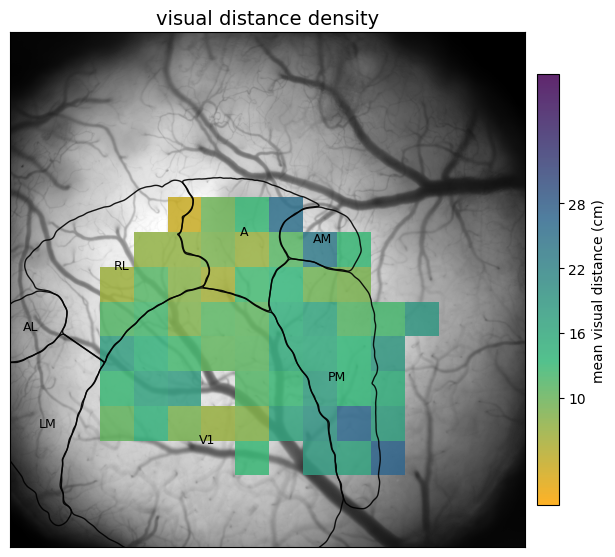

In [41]:
import os, pandas as pd, matplotlib.pyplot as plt
from widefield_viz import WidefieldCellPlotter

DIR = r"D:\data-distance-coding-project\mini2p-data\LDR004"
REF = os.path.join(DIR, "sign-map", "reference.tif"); SM = os.path.join(DIR, "sign-map")
vis = pd.read_pickle(os.path.join(DIR, "LDR004_sessions_visual.pkl"))
LDR004 = WidefieldCellPlotter(vis, REF, sign_map_dir=SM)

%load_ext autoreload
%autoreload 2

LDR004.plot_cells(feature="angle",    zoom=True)   # visual RF angle, keep cells colored / rest grey
LDR004.plot_cells(feature="distance", zoom=True)
LDR004.plot_cell_density(zoom=False, vmin = 0, vmax=50, n_bins=10, min_count=10)
LDR004.plot_cell_density(feature="distance",zoom=False, vmin = 0, vmax=40, n_bins=10, min_count=10)
plt.show()

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'visual distance density'}>)

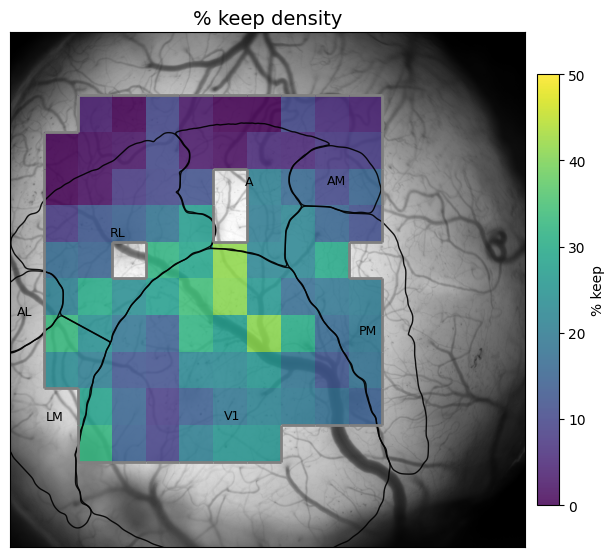

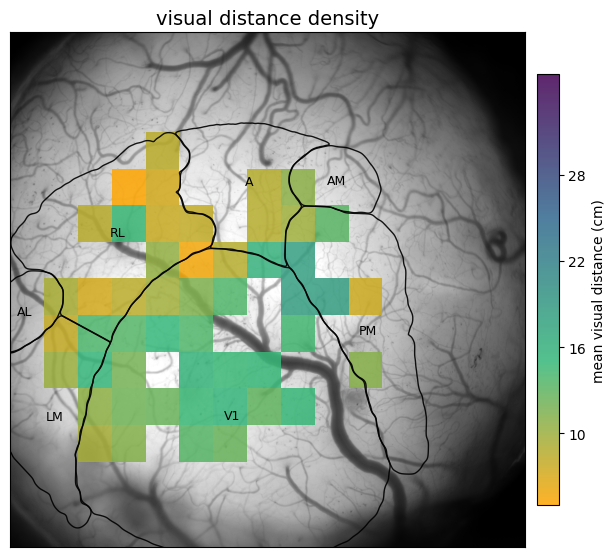

In [44]:
import os, sys, importlib
import pandas as pd

MINI2P = r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis"
if MINI2P not in sys.path:
    sys.path.insert(0, MINI2P)
import widefield_viz; importlib.reload(widefield_viz)   # pick up the edited module
from widefield_viz import WidefieldCellPlotter

# --- DMM065 single-animal plotter (visual table) ---
DIR = os.path.join(r"D:\data-distance-coding-project\mini2p-data", "DMM065")
df  = pd.read_pickle(os.path.join(DIR, "DMM065_sessions_visual.pkl"))
DMM065 = WidefieldCellPlotter(df,
                              os.path.join(DIR, "sign-map", "reference.tif"),
                              sign_map_dir=os.path.join(DIR, "sign-map"))

DMM065.plot_cell_density(zoom=False, vmin=0, vmax=50, n_bins=10, min_count=10)
DMM065.plot_cell_density(feature="distance", zoom=False, vmin=5, vmax=35, n_bins=10, min_count=10)


  DMM065 (reference): rot=0.0 scale=1.00 dx=0 dy=0 r=1.000 n_cells=9387
  LDR004: rot=7.0 scale=1.10 dx=13 dy=-43 r=0.691 n_cells=11704

Aligned 2 animals to 'DMM065' (work frame 400x400).


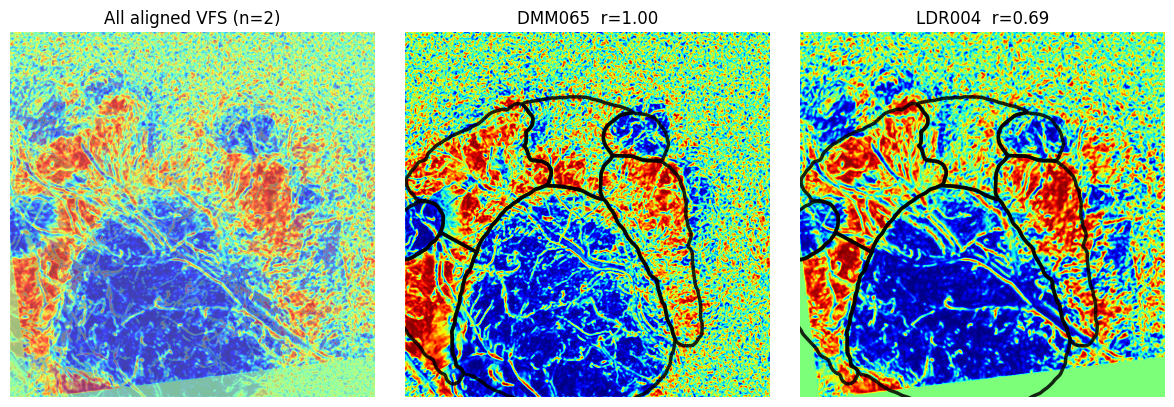

In [78]:
# === pooled VISUAL density across DMM065 + LDR004 (white bg, area-framed) ==
import importlib, widefield_viz, widefield_align
importlib.reload(widefield_viz); importlib.reload(widefield_align)

MINI2P = r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis"
if MINI2P not in sys.path:
    sys.path.insert(0, MINI2P)
import widefield_viz, widefield_align
importlib.reload(widefield_viz); importlib.reload(widefield_align)   # <-- picks up the new view mode
from widefield_align import MultiAnimalAligner, DATA_ROOT

animals = ["DMM065", "LDR004"]
all_df = pd.concat(
    [pd.read_pickle(os.path.join(DATA_ROOT, a, f"{a}_sessions_visual.pkl")).assign(animal=a)
     for a in animals],
    ignore_index=True)

aligner = MultiAnimalAligner(all_df)
aligner.align(reference="DMM065")
aligner.plot_alignment()                       # QC: confirm Pearson r before trusting the pool

pooled = aligner.make_pooled_plotter()          # white bg + area-boundary frame, by default

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'preferred distance  (n=3655)'}, xlabel='preferred distance (cm)', ylabel='cell count'>)

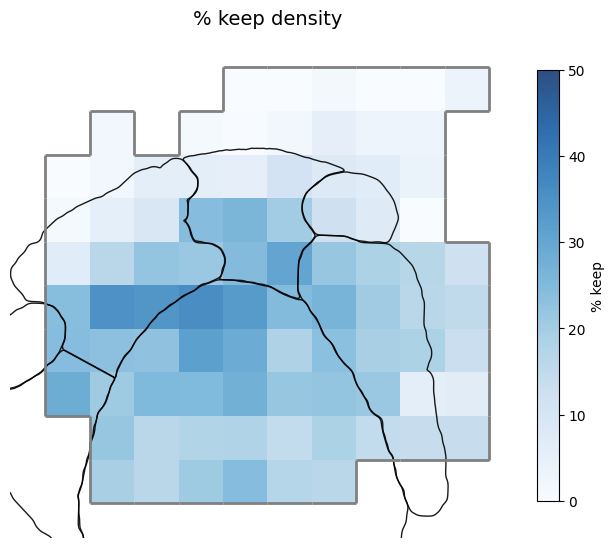

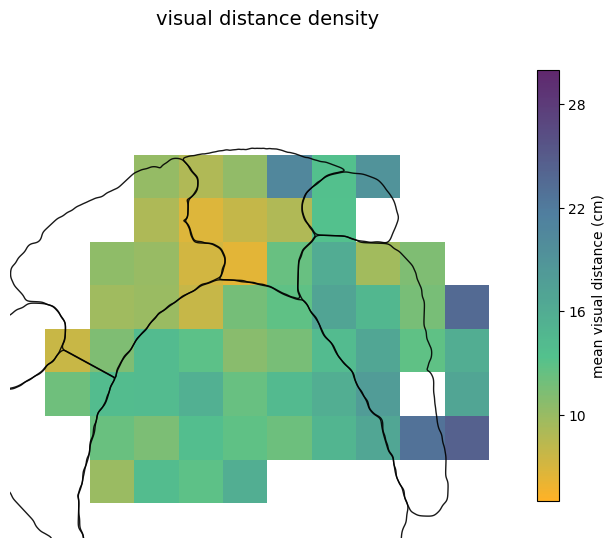

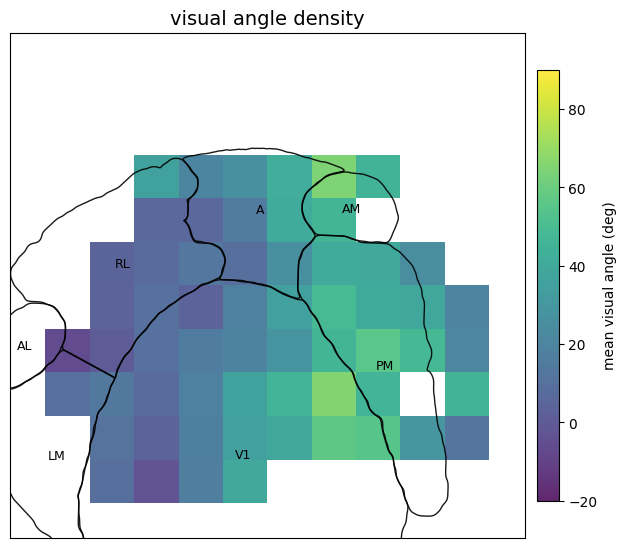

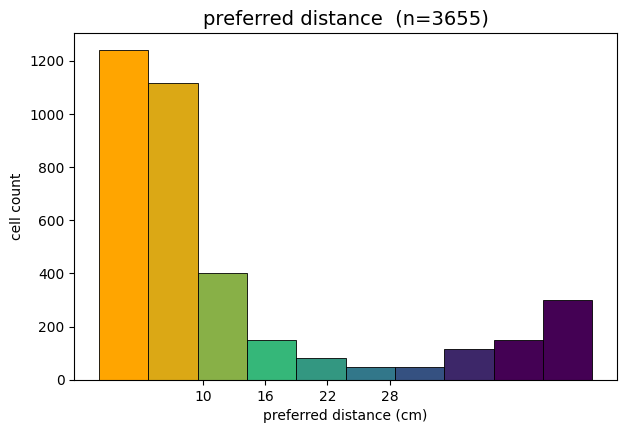

In [84]:
pooled.plot_cell_density(cmap='Blues', frame=False, label_areas=False, zoom=True, vmin=0, vmax=50, n_bins=10, min_count=20)
pooled.plot_cell_density(feature="distance", frame=False, label_areas=False, zoom=True, vmin=5, vmax=30, n_bins=10, min_count=20)
pooled.plot_cell_density(feature="angle", zoom=False, vmin=-20, vmax=90, n_bins=10, min_count=20)
pooled.plot_distance_histogram(n_bins=10, vmin=5, vmax = 40)

(<Figure size 1350x900 with 9 Axes>,
 array([<Axes: title={'center': 'V1  (n=1778)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'LM  (n=74)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'RL  (n=534)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'AM  (n=79)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'PM  (n=581)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'AL  (n=7)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: title={'center': 'A  (n=393)'}, xlabel='preferred distance (cm)', ylabel='cell count'>,
        <Axes: >, <Axes: >], dtype=object))

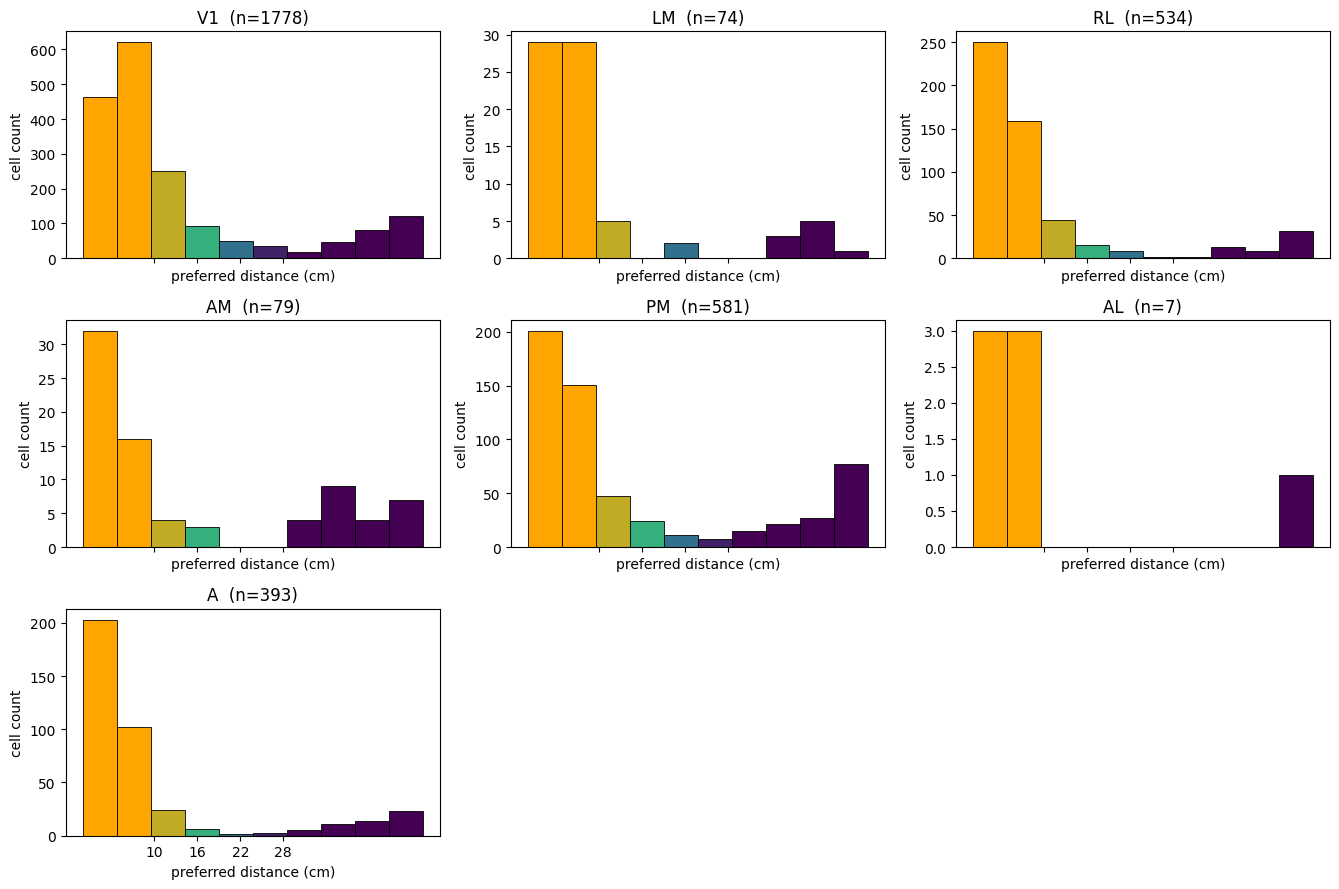

In [ ]:
pooled.plot_distance_histograms_by_area(n_bins=10, )

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'visual distance density'}>)

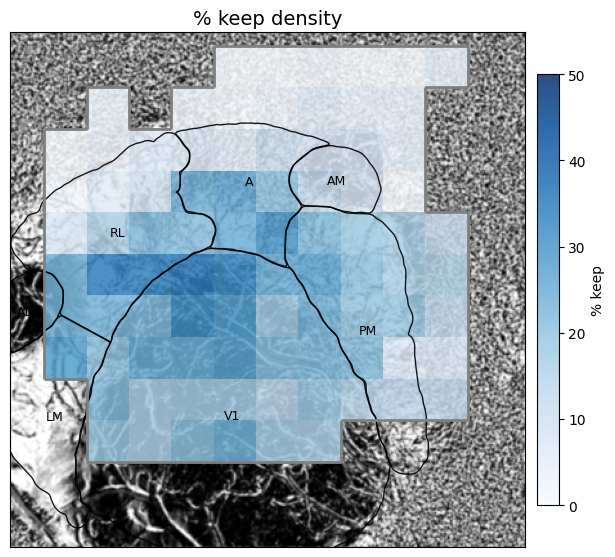

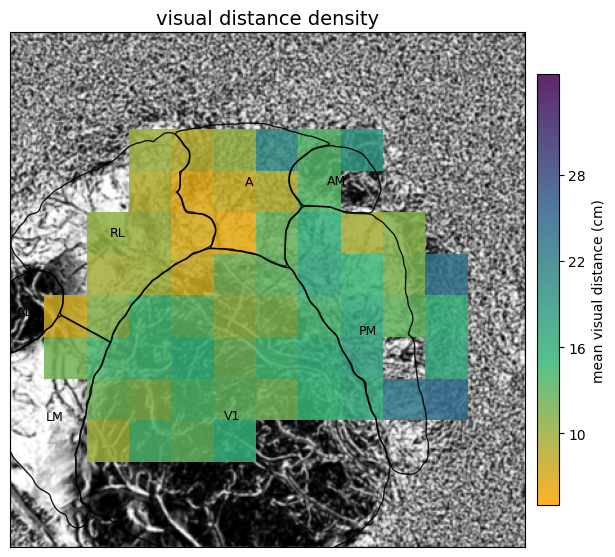

In [49]:
# 3) pooled plotter -> your two plots, now across both animals
pooled = aligner.make_pooled_plotter()
pooled.plot_cell_density(zoom=False, vmin=0, vmax=50, n_bins=10, min_count=20, cmap='Blues')
pooled.plot_cell_density(feature="distance", zoom=False, vmin=5, vmax=35, n_bins=10, min_count=20)

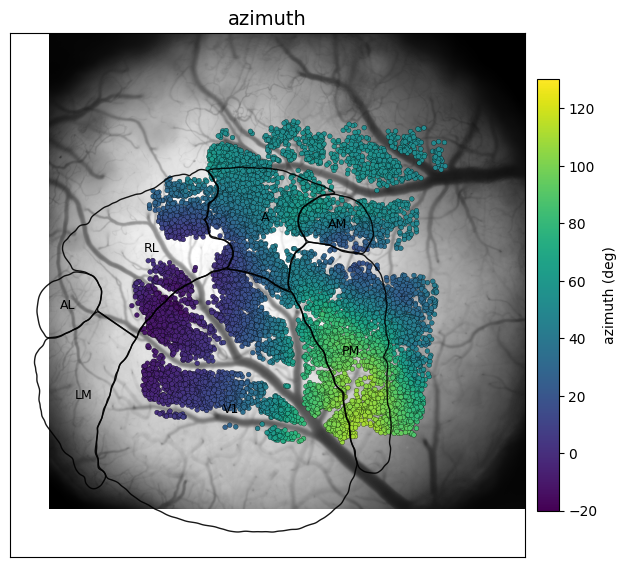

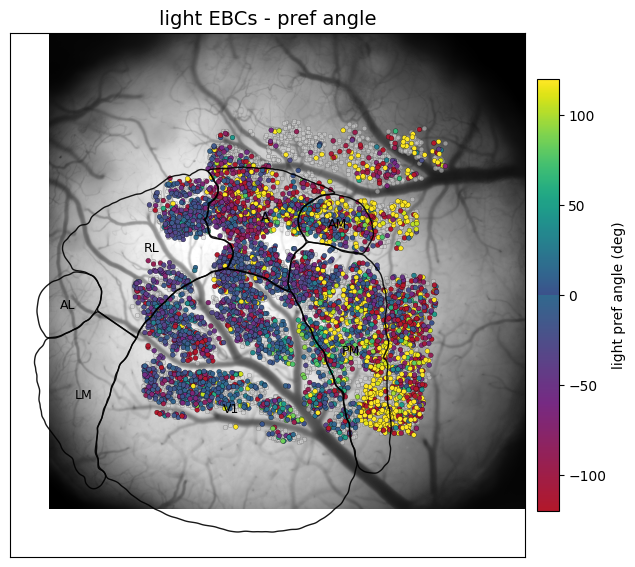

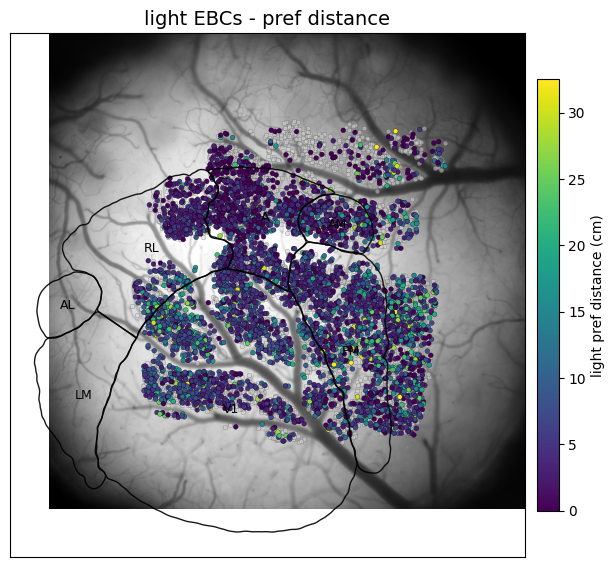

In [8]:
# ---------------------------------------------------------------- whole-mouse maps
# all cells share the same widefield frame, so the whole df overlays on one reference
plotter = WidefieldCellPlotter(df, REF, sign_map_dir=SM)   # SM = ...\LDR004\sign-map

plotter.plot_cells(condition="light", feature="azi", zoom=False, show_areas=True)
plotter.plot_cells(condition="light", feature="angle",    zoom=False)
plotter.plot_cells(condition="light", feature="distance",    zoom=False)
plt.show()

(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'light EBCs - pref angle'}>)

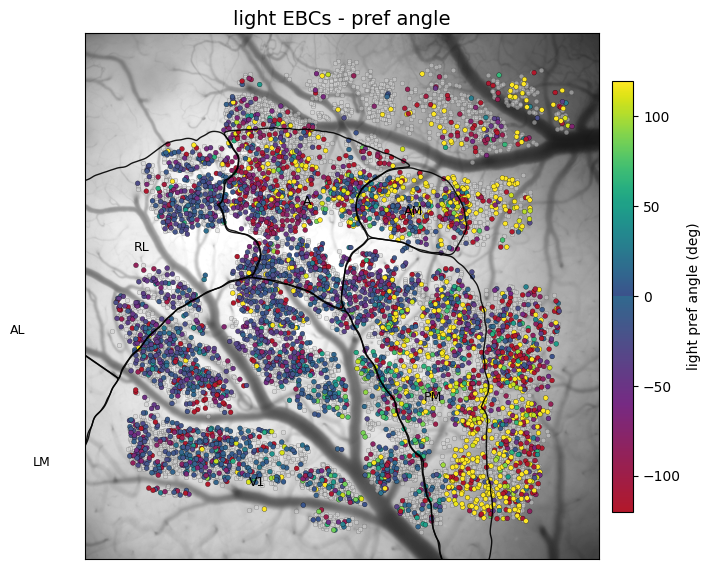

In [9]:
# light EBCs colored by preferred distance, non-EBCs greyed out
plotter.plot_cells(condition='light', feature='angle',zoom=True)

# # preferred angle (cyclic colormap), all cells
# plotter.plot_cells(feature="light_pref_angle", classified_col="light_is_ebc")

# # dark EBCs over the full reference
# plotter.plot_cells(feature="dark_pref_dist", classified_col="dark_is_ebc", zoom=False)

In [4]:
path = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251121_LDR_LDR004_ltdk_19.pkl"

In [5]:
with open(path, 'rb') as file:
    data = pickle.load(file)

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_38244\3807975402.py:2: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  data = pickle.load(file)


In [4]:
type(data)

dict

In [6]:
data.keys()

dict_keys(['settings', 'plot_settings', 'df', 'corners_df', 'ego_occ', 'ego_spk', 'ego_norm', 'allo_occ', 'allo_spk', 'allo_norm', 'max_projection_fig', 'max_projection_rois_fig', 'max_projection_array', 'roi_coordinates', 'invcl_outputs', 'ebcc_settings', 'ebcc_outputs_light', 'ebcc_outputs_dark', 'visual_invariance_mrl'])

In [7]:
data['settings']

{'rec_id': 0,
 'rec_name': '251121_LDR_LDR004_ltdk_19',
 'rec_path': 'C:\\Users\\lrandt\\Desktop\\combined_pre-processed\\251121_LDR_LDR004_ltdk_19',
 'output_subfolder': 'C:\\Users\\lrandt\\Desktop\\combined_post-processed\\251121_LDR_LDR004_ltdk_19',
 'likelihood_thr': 0.6,
 'jump_thr': 31.7,
 'spk_bool_thr_percentile': 90,
 'shift_neural_activity_frames': -2,
 'nr_cells': 535,
 'sampling_rate': 7.49,
 'ego_rays_deg': 3,
 'ego_radius': 0.35,
 'ego_bin_size': 0.025,
 'allo_bin_size': 0.02,
 'pix_scalar': 0.000285038337656415}

In [8]:
# data['df'] is the main dataframe

# all coordinates in meters, with (0,0) top left of camera FOV
# light = 0 is lights ON
# spk_rate is OASIS calcium events
# hd_radians/degrees = 0 is pointing right in camera FOV, goes clockwise
# ray_distances:
#   List of egocentric wall distances along 120 rays, spaced 3° apart.
#   Idx 0 = ahead, idx 1 = 3° left, idx 2 = 6° left, ..., 
#   idx 30 = 90° left, idx 60 = behind, idx 90 = 90° right

data['df'].head()

,rec_id,frame,t_sec,x,y,hd_radians,hd_degrees,pad_nose_x,pad_nose_y,pad_nose_likelihood,pad_r_x,pad_r_y,pad_r_likelihood,light,trial,spk_rate,spk_bool,spk_rate_thr,ray_distances
0,0,0,0.00,0.554,0.474,3.233055,185.240397,0.537,0.475,0.802027,0.571,0.472,0.632043,0,0,"[0.0, 0.0, 0.0, 0.0, 0.0, 247.4587, 0.0, 0.0, ...","[False, False, False, False, False, True, Fals...","[0.0, 0.0, 0.0, 0.0, 0.0, 247.4587, 0.0, 0.0, ...","[0.49, 0.493, 0.398, 0.318, 0.266, 0.229, 0.20..."
1,0,1,0.13,0.556,0.469,2.999162,171.839340,0.542,0.467,0.800518,0.570,0.471,0.879074,0,0,"[0.0, 0.0, 0.0, 0.0, 0.0, 274.59137, 0.0, 0.0,...","[False, False, False, False, False, True, Fals...","[0.0, 0.0, 0.0, 0.0, 0.0, 274.59137, 0.0, 0.0,...","[0.494, 0.492, 0.49, 0.49, 0.491, 0.494, 0.478..."
2,0,2,0.27,0.560,0.470,3.012510,172.604088,0.543,0.467,0.826288,0.578,0.472,0.718620,0,0,"[0.0, 0.0, 59.63055, 0.0, 0.0, 58.223434, 0.0,...","[False, False, False, False, False, False, Fal...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.498, 0.495, 0.494, 0.494, 0.496, 0.499, 0.4..."
3,0,3,0.40,0.559,0.469,2.972162,170.292348,0.541,0.466,0.727545,0.577,0.472,0.752048,0,0,"[0.0, 0.0, 2.7245932, 0.0, 0.0, 44.799416, 0.0...","[False, False, False, False, False, False, Fal...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.499, 0.496, 0.493, 0.493, 0.493, 0.495, 0.4..."
4,0,4,0.53,0.556,0.469,3.088586,176.962950,0.539,0.468,0.863692,0.572,0.469,0.727847,0,0,"[0.0, 0.0, 0.0, 0.0, 0.0, 143.02022, 0.0, 19.2...","[False, False, False, False, False, True, Fals...","[0.0, 0.0, 0.0, 0.0, 0.0, 143.02022, 0.0, 0.0,...","[0.49, 0.49, 0.49, 0.493, 0.496, 0.399, 0.323,..."


In [8]:
# data['corners_df'] shows coords of square arena's corners

data['corners_df'].head()

,rec_id,corner_nr,x_y_coords,x_y_coords_m
4,1,0,"[172.61714285714285, 1951.4514285714286]","[0.05, 0.56]"
5,1,1,"[187.24571428571429, 157.98857142857142]","[0.05, 0.05]"
6,1,2,"[2074.3314285714287, 172.61714285714285]","[0.59, 0.05]"
7,1,3,"[2059.7028571428573, 1963.1542857142856]","[0.59, 0.56]"


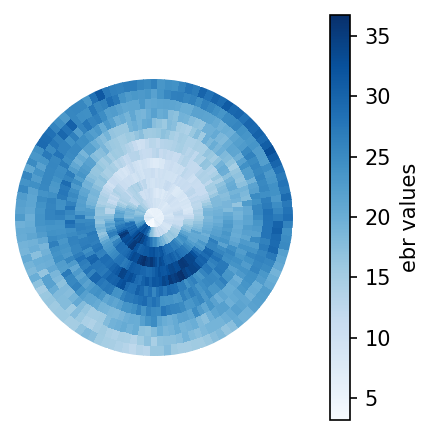

In [ ]:
# data['ego_norm'] has occupancy-normalized egocentric boundary receptive fields

# data['ego_norm'].shape = (nr_cells,)
# data['ego_norm'][cell].shape = (angular_bins, distance_bins), where:
#   angular_bins[0] = ahead, angular_bins[30] = left, etc.
#   distance_bins[0] = closest, centered at 0.0125m (covers 0-2.5cm)
#   distance_bins[-1] = farthest, centered at 0.3375m (covers 32.5-35cm)

def plot_ebr(ebr, figsize=(3, 3), dpi=150, title=None, colorbar=True, cmap='Blues'):
    '''
    Parameters:
    - ebr: np.array object of shape (120, 14)
    - figsize: Optional tuple for the figure size (default (4, 4))
    - dpi: Optional integer for the figure DPI (default 200)
    - title: Optional string for the plot title
    - colorbar: Optional boolean to show/hide colorbar (default True)
    - cmap: Optional string for the colormap (default 'Blues')
    '''
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi, subplot_kw={'projection': 'polar'})
    theta = np.linspace(0, 2*np.pi, ebr.shape[0], endpoint=False)  # angles
    r = np.linspace(0, 1, ebr.shape[1])  # radii values normalized 0-1
    theta_grid, r_grid = np.meshgrid(theta, r)
    cax = ax.pcolormesh(theta_grid, r_grid, ebr.T, cmap=cmap)
    
    if colorbar:
        cbar = fig.colorbar(cax, ax=ax, pad=0.1)
        cbar.set_label('ebr values')
    
    ax.set_theta_zero_location('N') # Make angular bin 0 point up in plot
    ax.set_yticks([])  # Remove radial ticks
    ax.set_xticks([])  # Remove angular ticks
    ax.set_yticklabels([])  # Remove radial tick labels
    ax.set_xticklabels([])  # Remove angular tick labels
    ax.spines['polar'].set_visible(False)  # Remove the outer circle
    
    if title:
        ax.set_title(title)
    
    plt.tight_layout()
    plt.show()

cell_id = 7
plot_ebr(data['ego_norm'][cell_id])

In [106]:
from cell_explorer import CellExplorer

EBR = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251204_LDR_LDR004_ltdk_10.pkl"
ce = CellExplorer(EBR)
                          # or fig.savefig(...)

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  self.settings = ebr["settings"]


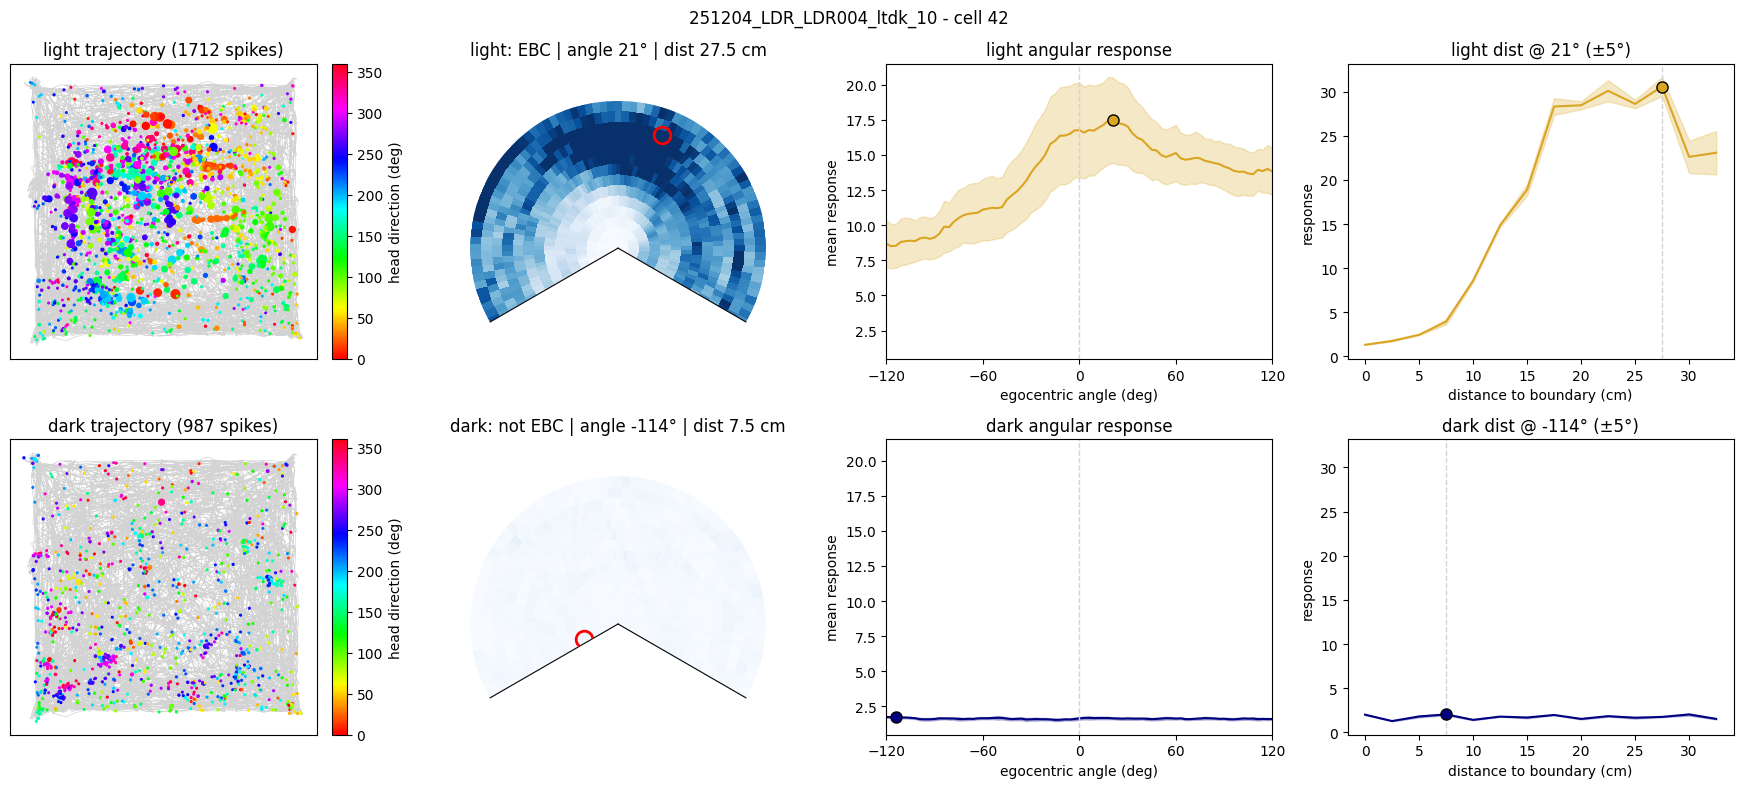

In [193]:
fig = ce.plot_cell(42)

In [10]:
data['ebcc_outputs_light'].keys()

dict_keys(['nr_ebcs', 'ebcs_ids', 'ebcs_mask', 'mrl_criterion_met', 'cc_criterion_met', 'mrs_all_cells', 'mrls_all_cells', 'mras_all_cells', 'pref_dists_all_cells', 'ebr_cc_all_cells', 'mrs_ebcs', 'mrls_ebcs', 'mras_ebcs', 'pref_dists_ebcs', 'ebr_cc_ebcs', 'df_ebcs'])

In [11]:
# data['ebcc_outputs_light'] is dict with EBC classification outputs (same for data['ebcc_outputs_dark'])

print(data['ebcc_outputs_light'].keys())

# has the ids of cells that passed all criteria checks:
print('EBC IDs:', data['ebcc_outputs_light']['ebcs_ids'][:5], '...')

# also has preferred tuning angle and distance of all cells:
print('Mean resultant angles in radians:', data['ebcc_outputs_light']['mras_all_cells'][:5], '...')
print('Preferred distance (argmax along mean resultant angle bin, converted to m):', data['ebcc_outputs_light']['pref_dists_all_cells'][:5], '...')

dict_keys(['nr_ebcs', 'ebcs_ids', 'ebcs_mask', 'mrl_criterion_met', 'cc_criterion_met', 'mrs_all_cells', 'mrls_all_cells', 'mras_all_cells', 'pref_dists_all_cells', 'ebr_cc_all_cells', 'mrs_ebcs', 'mrls_ebcs', 'mras_ebcs', 'pref_dists_ebcs', 'ebr_cc_ebcs', 'df_ebcs'])
EBC IDs: [1 2 3 4 6] ...
Mean resultant angles in radians: [2.48503485 3.67149271 2.53025264 2.67536449 2.89304005] ...
Preferred distance (argmax along mean resultant angle bin, converted to m): [0.0125 0.0375 0.0125 0.0125 0.2625] ...
